[![Query.Farm](assets/query-farm-strata-sun.svg)](https://query.farm/)

[![VGI](assets/vgi-logo.png)](https://query.farm/vgi/)

# Does the average describe a typical post?

A few popular posts can lift the average far above the middle of a feed. We compare the mean, median and concentration of likes on the official **bsky.app** account’s own posts. The real Bluesky worker retrieves a bounded feed through Haybarn / VGI; SQL defines the population and calculates the distribution.

**Recorded public data by default.** The companion contains a projected public API response captured on **2026-11-14 at 05:17:23 UTC**. Only identifiers, timestamps, counts and feed reasons are retained; post text, media and profile descriptions are omitted. The upstream request asked for 100 items and returned 98 with a continuation cursor. Replay intentionally serves those 98 items only, so this is a bounded feed sample, not a full account history. `DATA_MODE = "live"` uses the public API directly and never falls back to the recording.

## Choose the observation window

`LOOKBACK_DAYS` is an integer from 1 to 90; default 30. The window includes its UTC start and excludes its end. Replay ends at the recording timestamp; live mode ends at one UTC time captured before retrieval. Both read at most 98 feed items, then filter locally. Changing the window cannot recover older items outside that bounded response. Restart and run all after changing a parameter.

In [1]:
DATA_MODE = "replay"  # "replay" or "live"; no credentials needed
LOOKBACK_DAYS = 30  # UTC calendar-length days before the observation time; 1–90

In [2]:
import json
import os
from datetime import UTC, datetime, timedelta
from pathlib import Path

import haybarn
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import display

from notebook_support import finish, prose, theme
from recorded_api import start_replay

if DATA_MODE not in {"replay", "live"}:
    raise ValueError('DATA_MODE must be "replay" or "live".')
if type(LOOKBACK_DAYS) is not int or not 1 <= LOOKBACK_DAYS <= 90:
    raise ValueError("LOOKBACK_DAYS must be an integer from 1 to 90.")
recording = json.loads(Path("data/official-feed.json").read_text())
for key in ("BLUESKY_APPVIEW_URL", "BLUESKY_SEARCH_URL"):
    os.environ.pop(key, None)
replay_server = None
if DATA_MODE == "replay":
    replay_server = start_replay()
    os.environ["BLUESKY_APPVIEW_URL"] = f"http://127.0.0.1:{replay_server.server_port}"
    observed = datetime.fromisoformat(recording["recorded_at_utc"])
else:
    observed = datetime.now(UTC)
WINDOW_END = observed.isoformat()
WINDOW_START = (observed - timedelta(days=LOOKBACK_DAYS)).isoformat()
source_label = f"{DATA_MODE} · public bsky.app feed · observed {observed:%Y-%m-%d %H:%M UTC}"
theme()
connection = haybarn.connect()
%load_ext sql
%config SqlMagic.autopandas = True
%config SqlMagic.feedback = False
%config SqlMagic.displaycon = False
%sql connection

/Users/rusty/Development/notebook-rollout/full-rollout/checkouts/vgi-bluesky/notebooks/.venv/lib/python3.14/site-packages/sql/parse.py:339: SyntaxWarning: "\:" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\:"? A raw string is also an option.
  Given a query, replaces all occurrences of ':variable' with '\:variable' and
/Users/rusty/Development/notebook-rollout/full-rollout/checkouts/vgi-bluesky/notebooks/.venv/lib/python3.14/site-packages/sql/parse.py:369: SyntaxWarning: "\:" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\:"? A raw string is also an option.
  Given a query, replaces all occurrences of 'example'[x:y] with 'example'[x\:y].


Tip: You may define configurations in /Users/rusty/Development/notebook-rollout/full-rollout/checkouts/vgi-bluesky/notebooks/pyproject.toml or /Users/rusty/.jupysql/config.

Did not find user configurations in /Users/rusty/Development/notebook-rollout/full-rollout/checkouts/vgi-bluesky/notebooks/pyproject.toml.

## Attach the pinned worker

The literal Git launcher resolves a published revision independently of this checkout. Replay uses the worker’s supported `BLUESKY_APPVIEW_URL` override and a loopback companion that serves only the recorded request. Live mode clears endpoint overrides and calls the normal public service. No login or write operation is involved.

In [3]:
%%sql
INSTALL vgi FROM community;
LOAD vgi;
ATTACH 'bluesky' (TYPE vgi,
    LOCATION 'uvx --python 3.13 --with vgi-python==0.51.1 --from git+https://github.com/Query-farm/vgi-bluesky@e7b043c1106e755b0083a4abbbbd66c49e145b9d vgi-bluesky'
);

,Success


## Freeze one bounded feed

Materialize the remote call before capturing a DataFrame, so charts and summaries reuse the same response. `posts_no_replies` excludes replies at the API; pinned posts are disabled. Reposts may still appear, with the original author and a `reason`. The row cap applies to this mixed feed **before** selecting the account’s own posts. Counts are cumulative observations at retrieval time, not likes earned during the selected window.

In [4]:
%%sql
CREATE TABLE feed AS
SELECT uri, author_did, author_handle, created_at, indexed_at, reason, like_count
FROM bluesky.main.author_feed('bsky.app', filter => 'posts_no_replies', include_pins => false)
LIMIT 98;

SELECT coalesce(reason, 'own post') AS feed_reason, count(*) AS feed_items,
       count(DISTINCT uri) AS distinct_posts,
       min(created_at) AT TIME ZONE 'UTC' AS earliest_created_utc,
       max(created_at) AT TIME ZONE 'UTC' AS latest_created_utc
FROM feed GROUP BY reason ORDER BY feed_items DESC;

,feed_reason,feed_items,distinct_posts,earliest_created_utc,latest_created_utc
0,repost,60,60,2026-05-23 17:16:29.301,2026-11-12 19:10:34.182
1,own post,38,38,2026-06-23 20:00:06.000,2026-11-13 22:03:20.663


## Define the comparison population

Keep original posts belonging to the official account’s recorded stable DID, then deduplicate post URIs. A handle can change; the DID is the identity key. Filter by the author-supplied creation timestamp in the selected half-open UTC window. This timestamp can be backdated, so it is not an independently verified publication clock. NULL like counts remain unavailable and are excluded from numerical summaries; a recorded zero remains a valid zero.

In [5]:
%%sql
CREATE TABLE own_posts AS
SELECT * FROM feed
WHERE reason IS NULL AND author_did = 'did:plc:z72i7hdynmk6r22z27h6tvur'
QUALIFY row_number() OVER (PARTITION BY uri ORDER BY indexed_at DESC NULLS LAST) = 1;

CREATE TABLE selected AS
SELECT * FROM own_posts
WHERE created_at >= CAST('{{WINDOW_START}}' AS TIMESTAMPTZ)
  AND created_at < CAST('{{WINDOW_END}}' AS TIMESTAMPTZ);

CREATE TABLE distribution AS
SELECT uri, created_at, like_count,
       row_number() OVER (ORDER BY like_count DESC, uri) AS popularity_rank,
       count(*) OVER () AS measured_posts,
       sum(like_count) OVER () AS total_likes,
       sum(like_count) OVER (ORDER BY like_count DESC, uri ROWS UNBOUNDED PRECEDING) AS cumulative_likes
FROM selected WHERE like_count IS NOT NULL;

SELECT count(*) AS selected_posts, count(like_count) AS measured_posts,
       count(*) FILTER (WHERE like_count IS NULL) AS unavailable_counts,
       min(created_at) AT TIME ZONE 'UTC' AS first_created_utc,
       max(created_at) AT TIME ZONE 'UTC' AS last_created_utc
FROM selected;

,selected_posts,measured_posts,unavailable_counts,first_created_utc,last_created_utc
0,15,15,0,2026-10-16 16:23:26.498,2026-11-13 22:03:20.663


In [6]:
%%sql summary <<
SELECT (SELECT count(*) FROM feed) AS feed_items,
       (SELECT count(*) FROM own_posts) AS unique_own_posts,
       (SELECT min(created_at) AT TIME ZONE 'UTC' FROM own_posts) AS oldest_own_created_utc,
       count(*) AS selected_posts, count(like_count) AS measured_posts,
       avg(like_count) AS mean_likes, median(like_count) AS median_likes,
       sum(like_count) AS total_likes, max(like_count) AS maximum_likes
FROM selected;

In [7]:
s = summary.iloc[0]
display(summary)
if s.measured_posts == 0:
    raise RuntimeError("No measured own posts in this bounded window. Choose a longer window; no result is fabricated.")

,feed_items,unique_own_posts,oldest_own_created_utc,selected_posts,measured_posts,mean_likes,median_likes,total_likes,maximum_likes
0,98,38,2026-06-23 20:00:06,15,15,3770.466667,2089.0,56557.0,15608


In [8]:
prose(
    f"**{DATA_MODE.title()} observation:** {WINDOW_START} ≤ created time < {WINDOW_END}. "
    f"The {int(s.feed_items)} retrieved feed items contain {int(s.unique_own_posts)} distinct own posts. "
    f"The window selects **{int(s.selected_posts)} posts**, with **{int(s.measured_posts)} known like counts** "
    f"and {int(s.selected_posts - s.measured_posts)} unavailable counts. "
    f"Mean likes are **{s.mean_likes:,.0f}**; the median is **{s.median_likes:,.0f}**. "
    "These summarize available posts in this bounded response, not every post or every user."
)
oldest = s.oldest_own_created_utc
if oldest is not None and oldest.to_pydatetime().replace(tzinfo=UTC) > datetime.fromisoformat(WINDOW_START):
    prose(
        "**Coverage warning:** the oldest own post returned is newer than the window start. "
        "The bounded feed may omit older posts inside your requested window."
    )

**Replay observation:** 2026-10-15T05:17:23.391655+00:00 ≤ created time < 2026-11-14T05:17:23.391655+00:00. The 98 retrieved feed items contain 38 distinct own posts. The window selects **15 posts**, with **15 known like counts** and 0 unavailable counts. Mean likes are **3,770**; the median is **2,089**. These summarize available posts in this bounded response, not every post or every user.

## See the whole distribution

Each step is a measured post. The curve shows the share of posts with **at most** the like count on the horizontal axis. The median describes the middle post; the mean can move farther right when a few counts are large. Both use the same measured population.

In [9]:
%%sql points <<
SELECT uri, created_at AT TIME ZONE 'UTC' AS created_utc, like_count,
       popularity_rank, measured_posts, total_likes, cumulative_likes,
       100.0 * popularity_rank / measured_posts AS cumulative_post_pct,
       100.0 * cumulative_likes / nullif(total_likes, 0) AS cumulative_like_pct
FROM distribution ORDER BY popularity_rank;

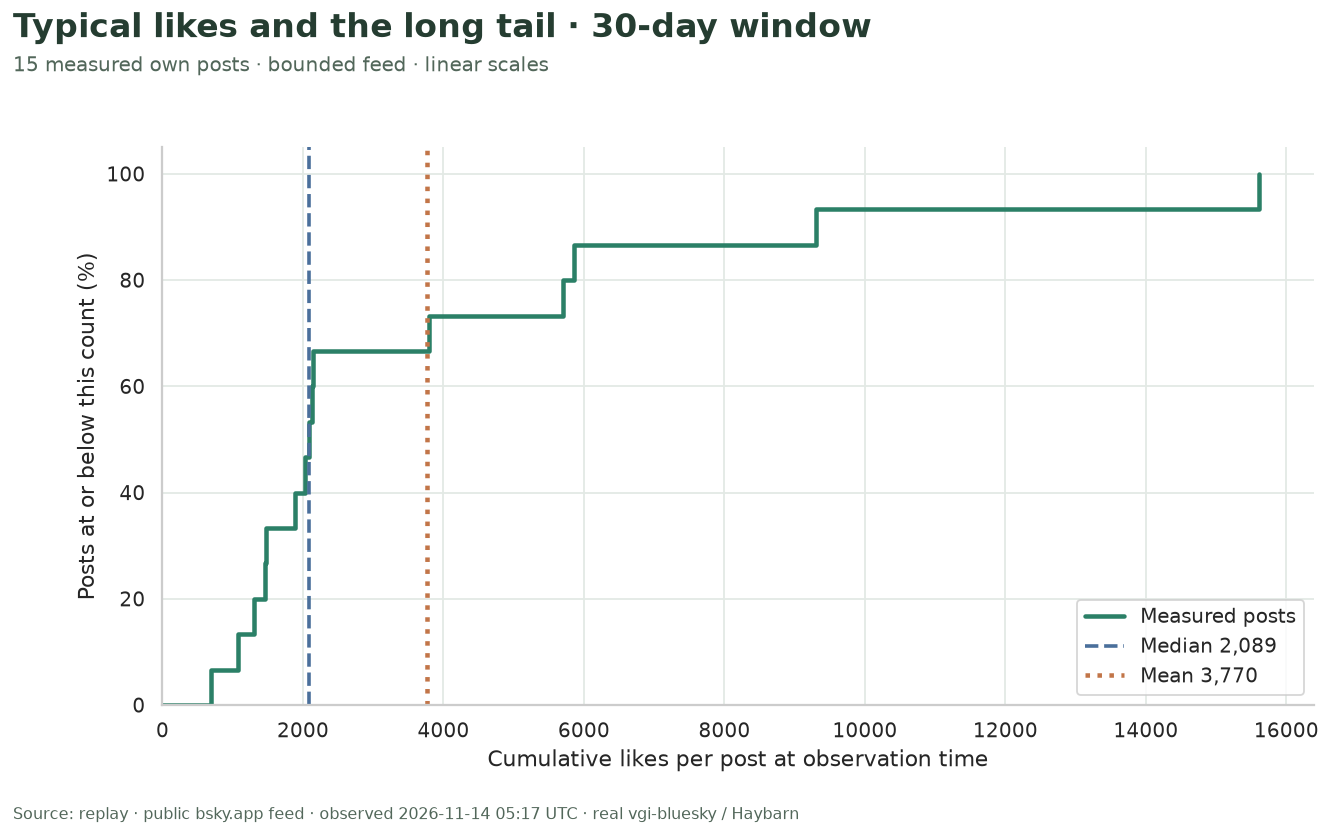

In [10]:
likes = np.sort(points.like_count.to_numpy())
fig, ax = plt.subplots(figsize=(11.5, 6.5))
ax.step(
    np.r_[0, likes],
    np.r_[0, 100 * np.arange(1, len(likes) + 1) / len(likes)],
    where="post",
    color="#2b8067",
    linewidth=2.5,
    label="Measured posts",
)
ax.axvline(s.median_likes, color="#4a6f9b", linestyle="--", linewidth=2, label=f"Median {s.median_likes:,.0f}")
ax.axvline(s.mean_likes, color="#c27548", linestyle=":", linewidth=2.5, label=f"Mean {s.mean_likes:,.0f}")
ax.set(
    xlabel="Cumulative likes per post at observation time",
    ylabel="Posts at or below this count (%)",
    ylim=(0, 105),
    xlim=(0, max(float(s.maximum_likes) * 1.05, 1)),
)
ax.legend(loc="lower right", frameon=True)
finish(
    fig,
    f"Typical likes and the long tail · {LOOKBACK_DAYS}-day window",
    f"{int(s.measured_posts)} measured own posts · bounded feed · linear scales",
    source_label,
    f"likes-distribution-{DATA_MODE}-{LOOKBACK_DAYS}.png",
)

## Measure concentration

Sort the same posts from most to least liked. The next curve asks how much of the observed like total is carried by the first fraction of posts. The diagonal would represent equal counts. The highlighted group contains the top `ceil(10% × measured posts)` posts, so its actual share of posts can exceed 10% in a small sample. Equal-count ties use URI order; their total is unchanged.

In [11]:
%%sql concentration <<
SELECT count(*) AS top_posts,
       max(measured_posts) AS measured_posts,
       sum(like_count) AS top_likes,
       max(total_likes) AS total_likes,
       100.0 * sum(like_count) / nullif(max(total_likes), 0) AS top_like_pct
FROM distribution WHERE popularity_rank <= ceil(0.1 * measured_posts);

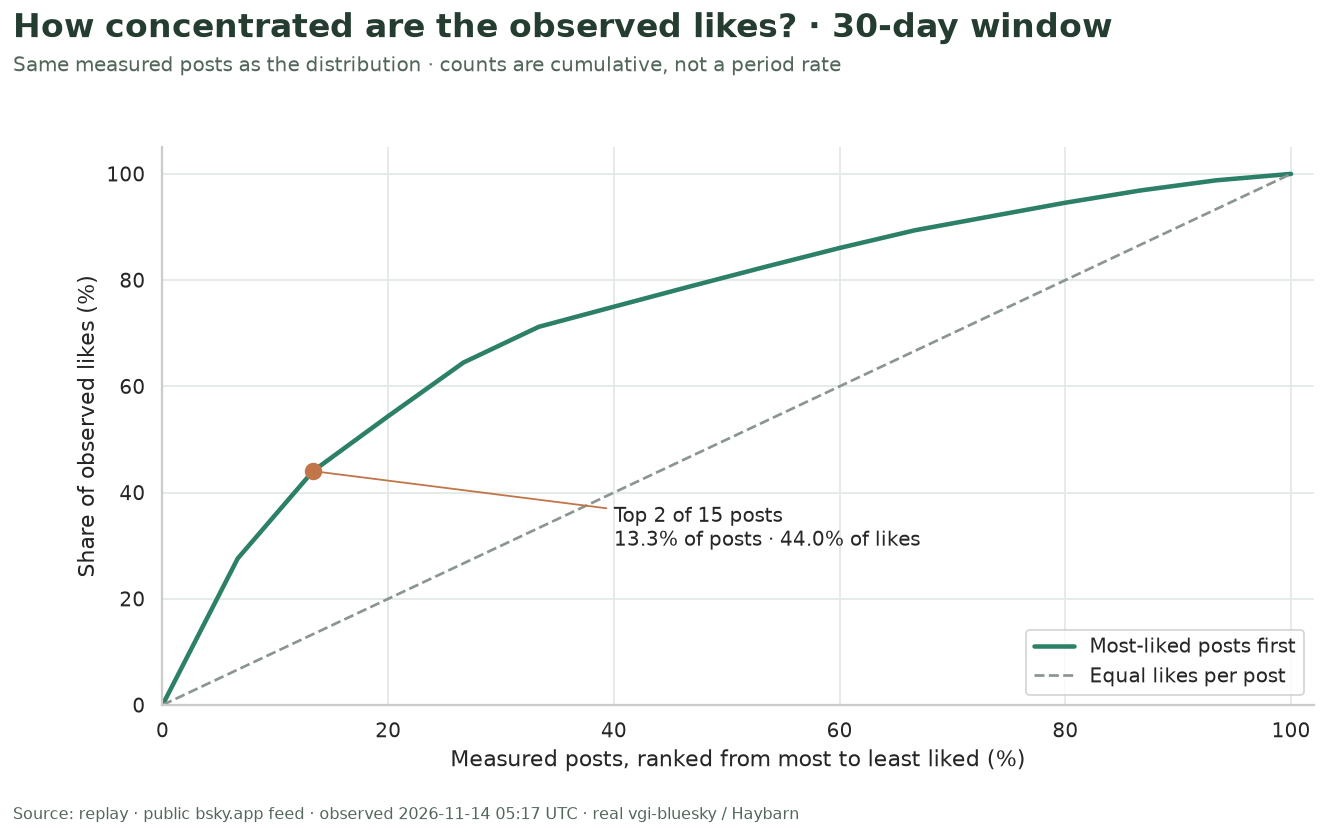

In [12]:
t = concentration.iloc[0]
fig, ax = plt.subplots(figsize=(11.5, 6.5))
if s.total_likes > 0:
    ax.plot(
        np.r_[0, points.cumulative_post_pct],
        np.r_[0, points.cumulative_like_pct],
        color="#2b8067",
        linewidth=2.5,
        label="Most-liked posts first",
    )
    ax.plot([0, 100], [0, 100], color="#8b9690", linestyle="--", label="Equal likes per post")
    top_x = 100 * t.top_posts / t.measured_posts
    ax.scatter([top_x], [t.top_like_pct], color="#c27548", s=75, zorder=3)
    ax.annotate(
        f"Top {int(t.top_posts)} of {int(t.measured_posts)} posts\n"
        f"{top_x:.1f}% of posts · {t.top_like_pct:.1f}% of likes",
        xy=(top_x, t.top_like_pct),
        xytext=(40, 30),
        textcoords="data",
        arrowprops={"arrowstyle": "-", "color": "#c27548"},
        fontsize=11,
    )
    ax.legend(loc="lower right")
else:
    ax.text(
        0.5,
        0.5,
        "All measured counts are zero; a share of total likes is undefined.",
        transform=ax.transAxes,
        ha="center",
        wrap=True,
    )
ax.set(
    xlabel="Measured posts, ranked from most to least liked (%)",
    ylabel="Share of observed likes (%)",
    xlim=(0, 102),
    ylim=(0, 105),
)
finish(
    fig,
    f"How concentrated are the observed likes? · {LOOKBACK_DAYS}-day window",
    "Same measured posts as the distribution · counts are cumulative, not a period rate",
    source_label,
    f"likes-concentration-{DATA_MODE}-{LOOKBACK_DAYS}.png",
)

In [13]:
if s.total_likes > 0:
    prose(
        f"The top **{int(t.top_posts)} of {int(t.measured_posts)} posts** account for "
        f"**{t.top_like_pct:.1f}%** of the **{int(t.total_likes):,} observed likes**. "
        "That concentration helps explain the distance between mean and median. "
        "Likes are not unique people, audience reach, or a controlled quality score. "
        "Older posts have had more time to accumulate responses; this comparison does not adjust for exposure or age."
    )
else:
    prose("All measured counts are zero. Mean and median are zero; concentration shares are undefined.")

The top **2 of 15 posts** account for **44.0%** of the **56,557 observed likes**. That concentration helps explain the distance between mean and median. Likes are not unique people, audience reach, or a controlled quality score. Older posts have had more time to accumulate responses; this comparison does not adjust for exposure or age.

## Check the population and arithmetic

These checks verify unique selected URIs, valid counts and window bounds, and agreement between aggregate and cumulative totals. They do not assert a fixed popularity ranking or claim full historical coverage.

In [14]:
%%sql checks <<
SELECT 'unique selected URIs' AS check_name, count(*) = count(DISTINCT uri) AS passed FROM selected
UNION ALL
SELECT 'known counts nonnegative', count(*) FILTER (WHERE like_count < 0) = 0 FROM selected
UNION ALL
SELECT 'within UTC window', count(*) FILTER (
    WHERE created_at < CAST('{{WINDOW_START}}' AS TIMESTAMPTZ)
       OR created_at >= CAST('{{WINDOW_END}}' AS TIMESTAMPTZ)) = 0 FROM selected
UNION ALL
SELECT 'cumulative and aggregate totals agree',
       max(cumulative_likes) = sum(like_count) FROM distribution
UNION ALL
SELECT 'measured population reconciles',
       count(*) = (SELECT count(like_count) FROM selected) FROM distribution
UNION ALL
SELECT 'concentration bounded',
       coalesce(bool_and(cumulative_like_pct BETWEEN 0 AND 100), true)
FROM (SELECT 100.0 * cumulative_likes / nullif(total_likes, 0) AS cumulative_like_pct FROM distribution);

In [15]:
display(checks)
assert checks.passed.all(), "A population or arithmetic invariant failed."

,check_name,passed
0,unique selected URIs,True
1,known counts nonnegative,True
2,within UTC window,True
3,cumulative and aggregate totals agree,True
4,measured population reconciles,True
5,concentration bounded,True


## Experiment: widen the creation window

Keep `DATA_MODE = "replay"` and change only **`LOOKBACK_DAYS` from 30 to 90**. Predict that the number of selected own posts cannot decrease because the response and window end are fixed. Predict separately whether the mean, median and top-group share will rise or fall; none is required to move in one direction. Run all and compare the diagnostics and both charts.

This experiment changes which posts enter the sample; it does not measure growth in likes over time. All counters still come from the same recorded observation, and the top group’s rounded size can change. Live runs are separate observations with changing posts and counters, so they are not a controlled comparison. Reset `LOOKBACK_DAYS = 30`. The README shows a command that saves the experiment separately.

In [16]:
connection.close()
if replay_server is not None:
    replay_server.shutdown()
    replay_server.server_close()
os.environ.pop("BLUESKY_APPVIEW_URL", None)

'http://127.0.0.1:54969'

[![Query.Farm](assets/query-farm-strata-sun.svg)](https://query.farm/)